# Лекция 2. Визуализация данных

**Дисциплина:** Анализ данных в Python  
**Тема:** Matplotlib, Seaborn, принципы эффективной визуализации

В этом ноутбуке:
- Базовые типы графиков в Matplotlib
- Статистические графики в Seaborn
- Тепловые карты, парные графики
- Принципы эффективной визуализации

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

## 1. Matplotlib: базовая структура

**Фигура** (`figure`) — холст. **Оси** (`axes`) — область для графика.  
На одной фигуре может быть несколько осей.

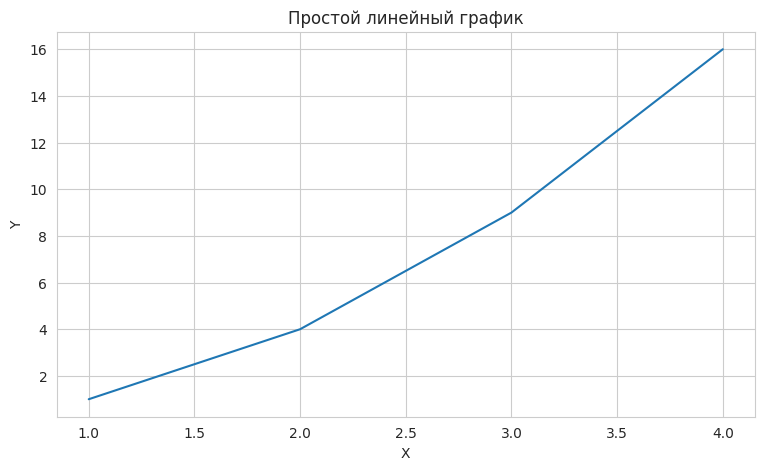

In [4]:
# Простой линейный график
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot([1, 2, 3, 4], [1, 4, 9, 16])
ax.set_title('Простой линейный график')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.show()

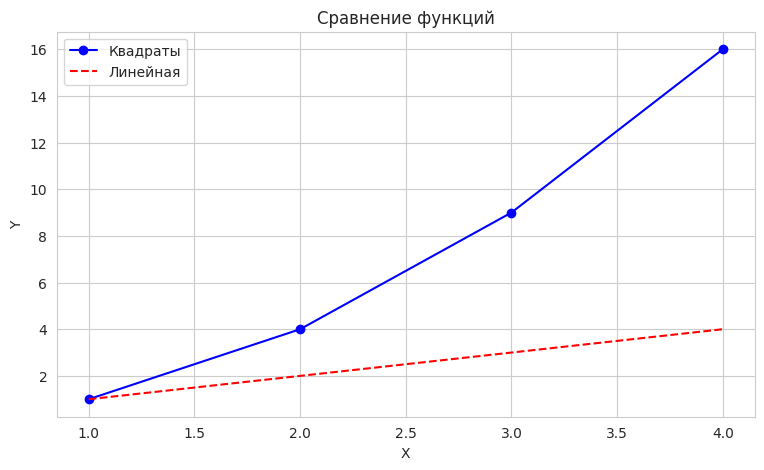

In [5]:
# Несколько линий с легендой
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot([1, 2, 3, 4], [1, 4, 9, 16],
        label='Квадраты', color='blue', marker='o')
ax.plot([1, 2, 3, 4], [1, 2, 3, 4],
        label='Линейная', color='red', linestyle='--')
ax.set_title('Сравнение функций')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.legend()
plt.show()

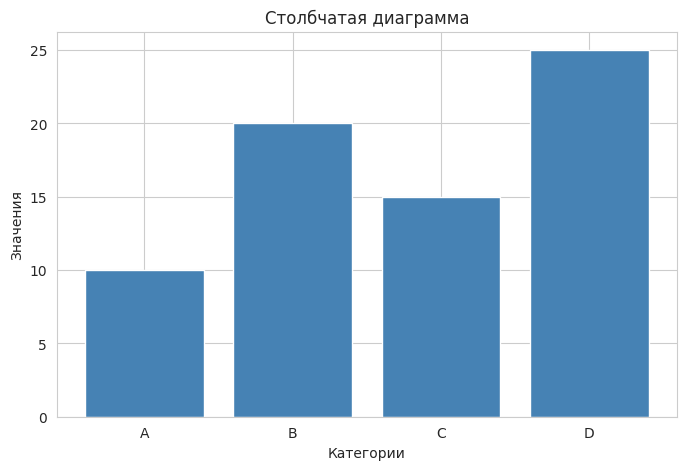

In [6]:
# Столбчатая диаграмма
categories = ['A', 'B', 'C', 'D']
values = [10, 20, 15, 25]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(categories, values, color='steelblue')
ax.set_title('Столбчатая диаграмма')
ax.set_xlabel('Категории'); ax.set_ylabel('Значения')
plt.show()

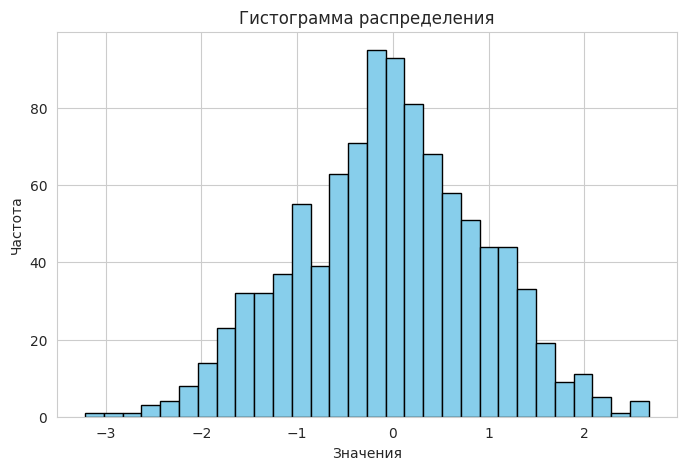

In [7]:
# Гистограмма распределения
data = np.random.randn(1000)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(data, bins=30, color='skyblue', edgecolor='black')
ax.set_title('Гистограмма распределения')
ax.set_xlabel('Значения'); ax.set_ylabel('Частота')
plt.show()

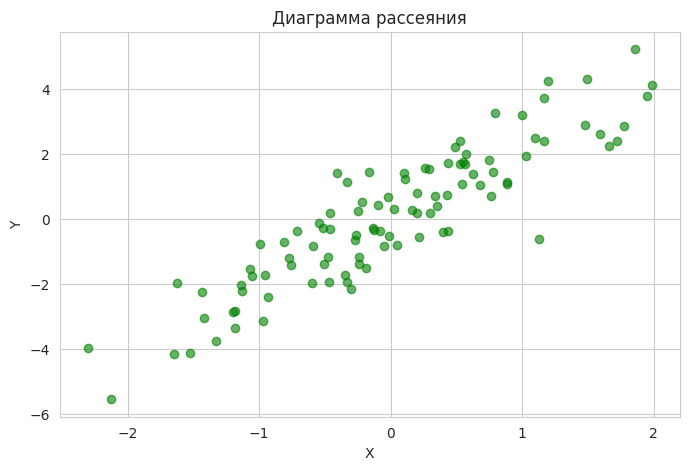

In [8]:
# Диаграмма рассеяния
x = np.random.randn(100)
y = 2 * x + np.random.randn(100)  # линейная зависимость + шум

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.6, c='green')
ax.set_title('Диаграмма рассеяния')
ax.set_xlabel('X'); ax.set_ylabel('Y')
plt.show()

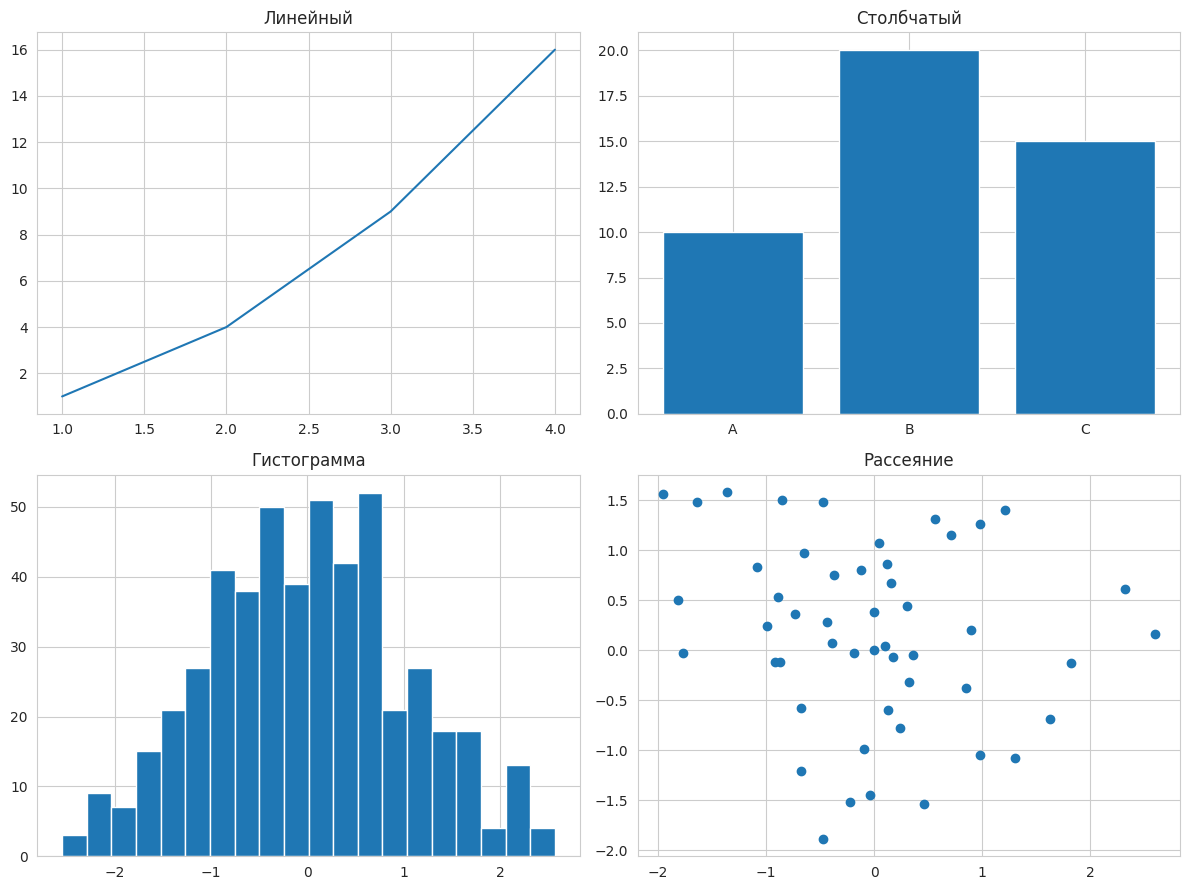

In [9]:
# Подграфики — 4 разных графика на одной фигуре
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].plot([1, 2, 3, 4], [1, 4, 9, 16])
axes[0, 0].set_title('Линейный')

axes[0, 1].bar(['A', 'B', 'C'], [10, 20, 15])
axes[0, 1].set_title('Столбчатый')

axes[1, 0].hist(np.random.randn(500), bins=20)
axes[1, 0].set_title('Гистограмма')

axes[1, 1].scatter(np.random.randn(50), np.random.randn(50))
axes[1, 1].set_title('Рассеяние')

plt.tight_layout()
plt.show()

## 2. Seaborn: работа с датасетом Titanic

In [10]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


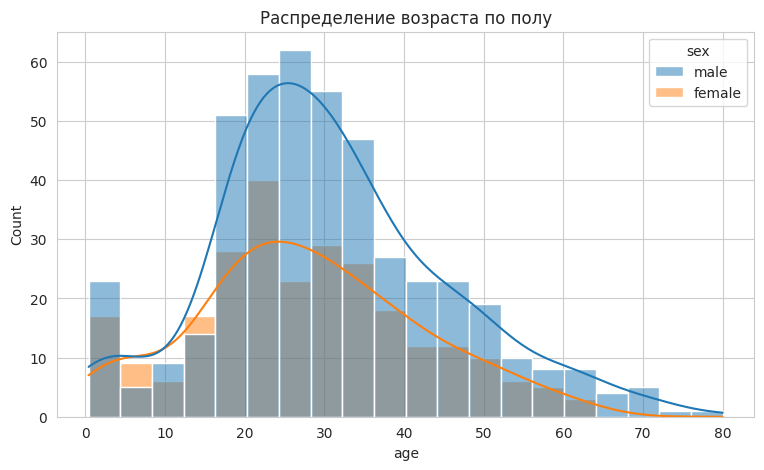

In [11]:
# Распределение возраста с разбивкой по полу
sns.histplot(data=df, x='age', hue='sex', kde=True)
plt.title('Распределение возраста по полу')
plt.show()

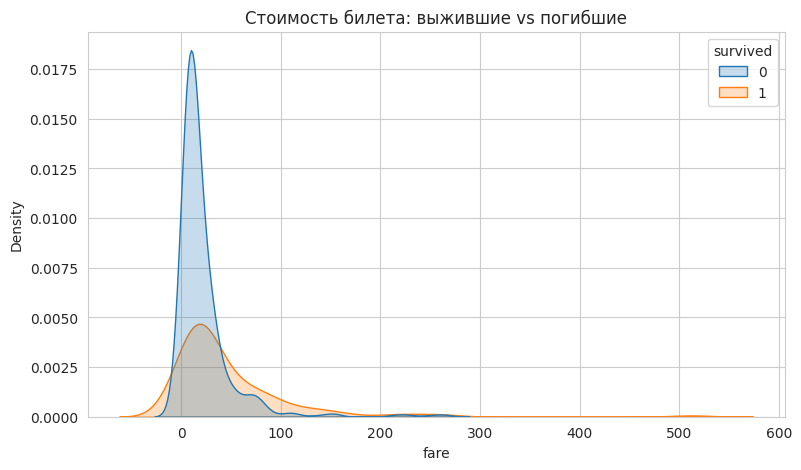

In [12]:
# Распределение стоимости билета по выживаемости
sns.kdeplot(data=df, x='fare', hue='survived', fill=True)
plt.title('Стоимость билета: выжившие vs погибшие')
plt.show()

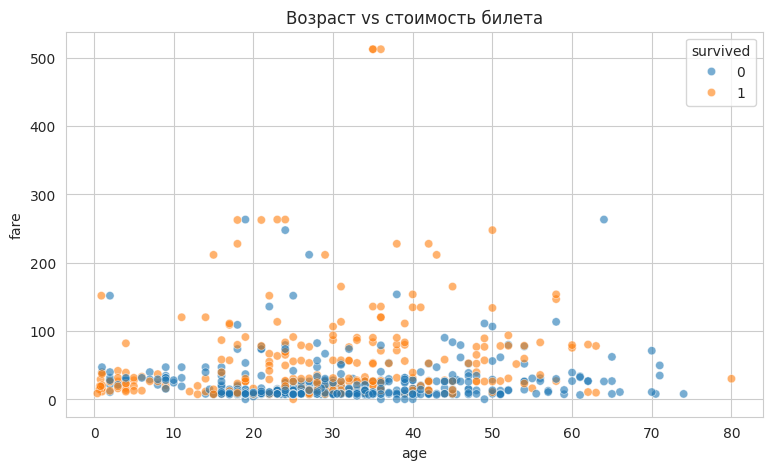

In [13]:
# Диаграмма рассеяния с разбивкой по категории
sns.scatterplot(data=df, x='age', y='fare', hue='survived', alpha=0.6)
plt.title('Возраст vs стоимость билета')
plt.show()

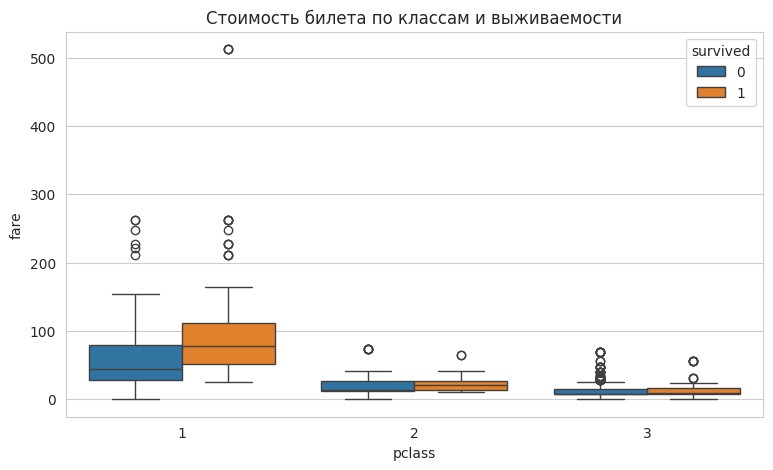

In [14]:
# Box-plot: стоимость билета по классам и выживаемости
sns.boxplot(data=df, x='pclass', y='fare', hue='survived')
plt.title('Стоимость билета по классам и выживаемости')
plt.show()

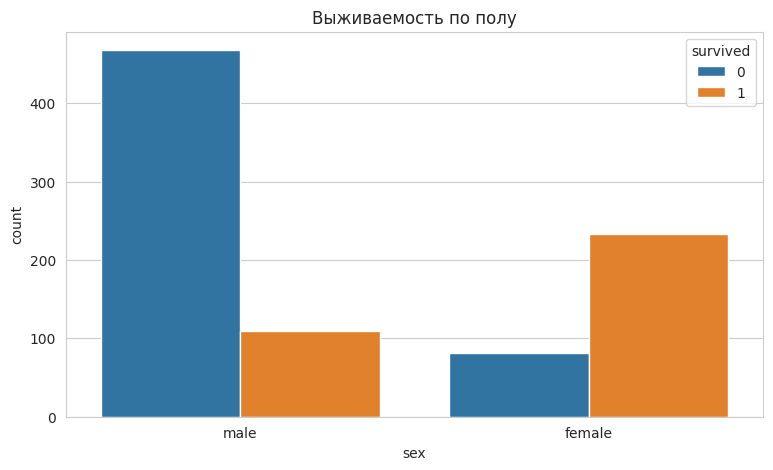

In [15]:
# Count-plot: выживаемость по полу
sns.countplot(data=df, x='sex', hue='survived')
plt.title('Выживаемость по полу')
plt.show()

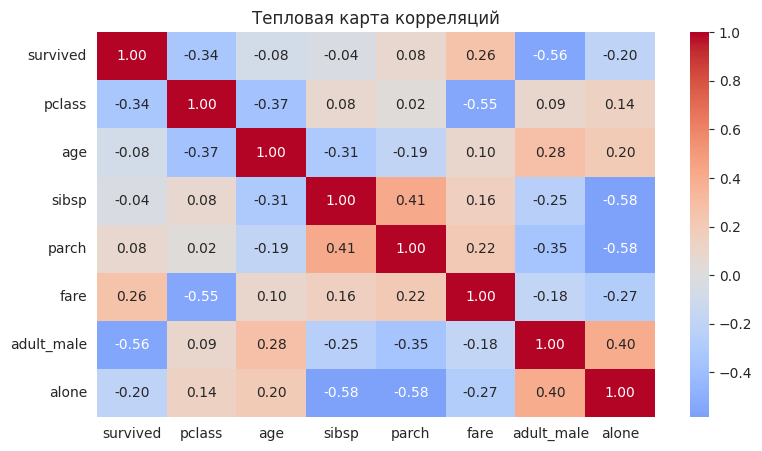

In [16]:
# Тепловая карта корреляций
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта корреляций')
plt.show()

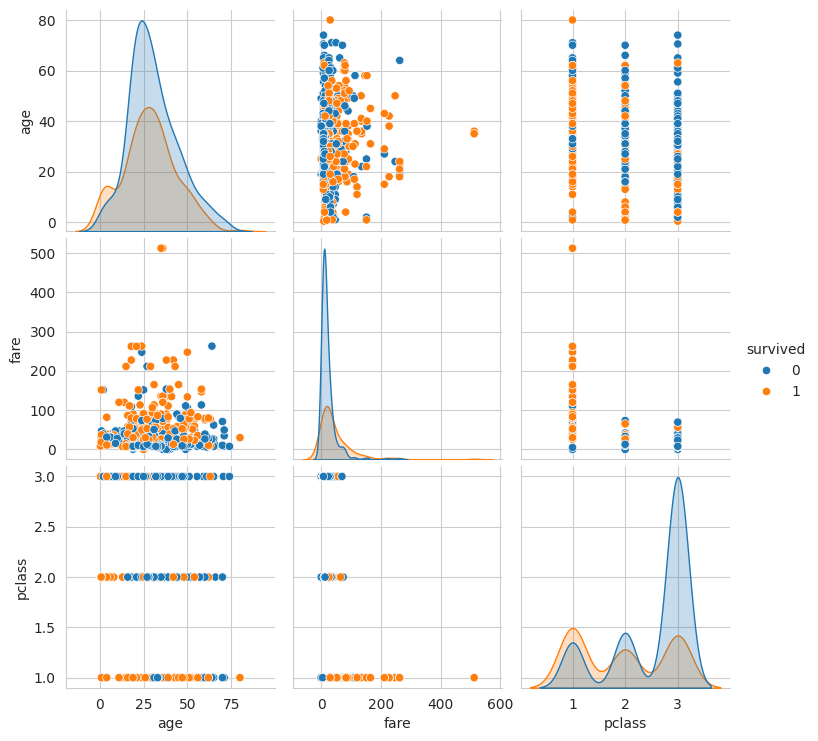

In [17]:
# Парные графики (pairplot) — матрица рассеяния
sns.pairplot(df[['age', 'fare', 'pclass', 'survived']], hue='survived')
plt.show()

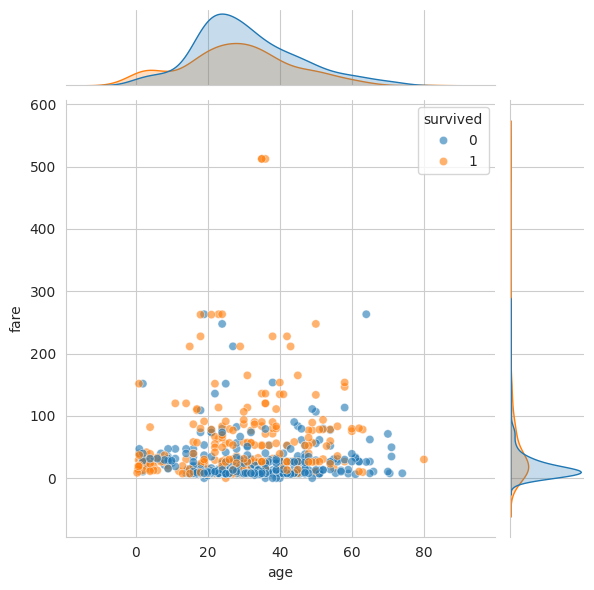

In [18]:
# Совместное распределение двух признаков
sns.jointplot(data=df, x='age', y='fare', hue='survived', alpha=0.6)
plt.show()

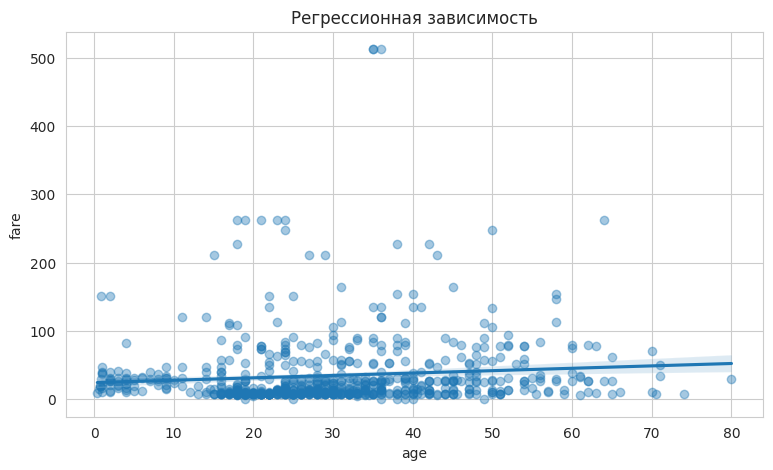

In [19]:
# Регрессионный график
sns.regplot(data=df, x='age', y='fare', scatter_kws={'alpha': 0.4})
plt.title('Регрессионная зависимость')
plt.show()

## 3. Принципы эффективной визуализации

1. **Тип графика под задачу** — гистограмма для распределения, scatter для связей, box-plot для сравнения групп.
2. **Не перегружать** — меньше линий, цветов и подписей.
3. **Подписи осей + заголовок** — обязательно.
4. **Осмысленный цвет** — цвет помогает, а не отвлекает.
5. **Не искажать** — обрезанная ось преувеличивает различия.
6. **Учитывать аудиторию** — для специалистов одни графики, для широкой публики — другие.

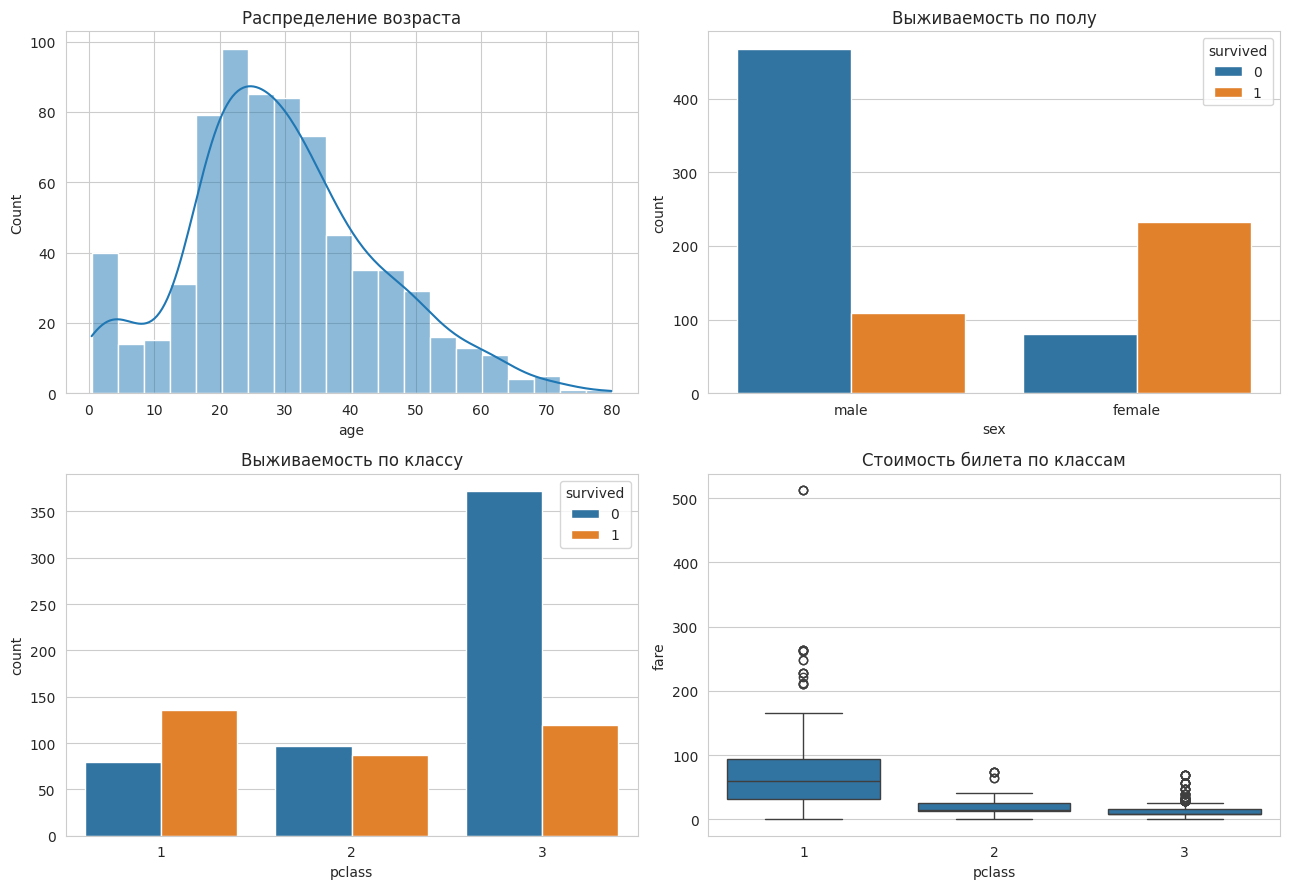

In [20]:
# Комплексный анализ: 4 графика в одной фигуре
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(data=df, x='age', kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Распределение возраста')

sns.countplot(data=df, x='sex', hue='survived', ax=axes[0, 1])
axes[0, 1].set_title('Выживаемость по полу')

sns.countplot(data=df, x='pclass', hue='survived', ax=axes[1, 0])
axes[1, 0].set_title('Выживаемость по классу')

sns.boxplot(data=df, x='pclass', y='fare', ax=axes[1, 1])
axes[1, 1].set_title('Стоимость билета по классам')

plt.tight_layout()
plt.show()

## Выводы по лекции 2

- Matplotlib — базовый инструмент, даёт полный контроль над графиком.
- Seaborn — надстройка с готовыми статистическими графиками.
- График без подписей и заголовка — бесполезен.
- Визуализация — это инструмент **анализа и коммуникации**, а не украшение.